<a href="https://colab.research.google.com/github/tavishgrade/nlp-language-model-portfolio/blob/main/Talktorial_5_Attention_TavishGrade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Talktorial 5 — Attention: Every Word Looks at Every Other Word

**Graduate NLP · Attention (Week 8 lecture) · Exposure #2** (lecture → **talktorial** → peer discussion)

The Embeddings lecture ended on three problems with reading a sentence in order — forgetting, the
bottleneck, no parallelism — and one question: *what if every word could look directly at every other
word?* The Attention lecture answered it: **queries, keys and values**, a **softmax** over scaled dot
products, a **weighted sum** — and the same move applied to a sentence looking at itself (**self-attention**),
with the future hidden (**masked**), several times in parallel (**multi-head**).

Here you push numbers through that formula **by hand**, find out why it says *scaled*, build self-attention
and masked self-attention yourself, and then open a real **BERT** and look at what its **144 heads**
actually attend to on our running word, **bass**.

> ⚠️ **Colab users — do this first:** **File → Save a copy in Drive.** Part 4 downloads BERT (~440 MB,
> a minute or two the first time; cached after that). Everything else runs in seconds on CPU.

**By the end you will be able to:**
1. Compute **scaled dot-product attention** from the formula, by hand, and say what each step does
2. Explain why the scores are **divided by √d** — and show what happens when they are not
3. Build **self-attention** and **masked self-attention** over a sentence from Q, K and V
4. Load a pretrained **BERT**, pull out its **attention weights**, and read a head's heat map
5. **Describe what real heads do** — with counts, not adjectives — and carry the claim into your Verification Log

**Submit:** answer the prediction questions below, run all cells (outputs saved), complete the
**AI Verification Log**, answer the **reflection questions** in the *Before you submit* cell, then upload the
`.ipynb` to Canvas by **Sun 11:59 PM**.

## Before you code: make some predictions

Type your answers in this cell (double-click to edit). **One or two sentences each, and every answer
needs a reason.** Predictions are graded for being real, not for being right.

- **Q1. In He landed a bass in the river, which one word should bass attend to most if attention
  is doing word-sense disambiguation — and why that word? Do you expect a real BERT head to do that?**
  > *Your answer:* River: If attention is doing word-sense disambiguation, 'bass' needs the context word that separates fish from music, and 'river' is the clearest signal (landed too, but landed could lean in many directions itself like land a plane). I expect a few real BERT heads to do it, but perhaps not cleanly.
- **Q2. The formula divides the scores by √d. If you leave that out, will the softmax weights get
  sharper (more weight on one word), flatter, or stay the same — and why?**
  > *Your answer:* Sharper: Without the division the dot products get bigger as the vectors get longer, and the softmax exponentiates, so a small lead in score becomes a big lead in weight. Dividing shrinks the scores back toward the flat part of the softmax.
- **Q3. BERT has 144 heads (12 layers × 12). When you look at them, what fraction do you expect to
  show a pattern you can name (previous word, next word, the sentence boundary, a grammatical relation),
  and what fraction no pattern you can read? Give a number and a reason.**
  > *Your answer:* I would guess 70% nameable and 30% unreadable. My guess is coming from the lecture slides showing positional and syntactics heads as if that is what heads are, so I assume most of the 144 would have a pattern I could name.

## Part 0 — Setup

Provided. Imports what we use (safe to re-run). `torch` and `transformers` are preinstalled on Colab.

> **Colab:** if an install finishes with a message asking you to **restart the runtime**, do that
> (**Runtime → Restart session**) and run this cell again. That is normal, not an error.

In [ ]:
import json, os   # used by the artifact cell in Part 7
import importlib.util, subprocess, sys
for pkg in ("torch", "transformers", "matplotlib"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import math
import numpy as np
import torch
import matplotlib.pyplot as plt
import transformers
transformers.logging.set_verbosity_error()     # hide the download/load chatter; errors still show
np.set_printoptions(precision=3, suppress=True)
torch.manual_seed(0); np.random.seed(0)
print("torch", torch.__version__, "· numpy", np.__version__, "ready")

torch 2.11.0+cpu · numpy 2.1.3 ready


## Part 1 — The formula, by hand

The lecture's formula: **Attention(q, K, V) = softmax( q·Kᵀ / √d ) · V**. One query *looks at* every key,
the softmax turns the scores into weights that sum to 1, and the output is the weighted sum of the values.

A three-word toy of our running sentence — *landed*, *bass*, *river* — with **made-up 2-dimensional
vectors** (illustrative, chosen so the arithmetic is easy to follow; real vectors have hundreds of
dimensions). The query is **bass** asking the sentence what it should pay attention to.

| word | key | value |
|---|---|---|
| landed | [1, 0] | [1, 0] |
| bass | [1, 1] | [0.5, 0.5] |
| river | [0, 2] | [0, 1] |

**Query for bass:** q = [0, 2]. Write `softmax` and `attention` from the formula — **no library
softmax** — and print each stage: scores, scaled scores, weights, output.

In [ ]:
# TODO: write softmax(x) and attention(q, K, V, scale=True) from the formula -- no library softmax.
#   softmax(x)              -> exponentiate, divide by the sum (subtract max(x) first so exp cannot overflow)
#   attention(q, K, V)      -> scores = q . k for every key; divide by sqrt(d) if scale; weights = softmax;
#                              output = weighted sum of the rows of V. Return (scores, weights, output),
#                              where `scores` are the SCALED scores (after the division) -- the check cell expects that.
# Then print the raw scores, the scaled scores, the weights (and their sum) and the output.

words = ["landed", "bass", "river"]
K = np.array([[1., 0.], [1., 1.], [0., 2.]])      # one key per word
V = np.array([[1., 0.], [.5, .5], [0., 1.]])      # one value per word
q = np.array([0., 2.])                            # bass is asking

def softmax(x):
    # subtracting the max changes nothing but stops exp overflowing
    e = np.exp(x - x.max())
    return e / e.sum()

def attention(q, K, V, scale=True):
    # one dot product per key
    scores = K @ q
    if scale:
      # divide by sqrt(d), d = length of a key
      scores /= math.sqrt(K.shape[1])
    weights = softmax(scores)
    # weighted sum of the rows of V
    output = weights @ V
    return scores, weights, output

raw = K @ q
scores, weights, output = attention(q, K, V)
print("raw scores     :", raw)
print("scaled scores  :", scores)
print("weights        :", weights, "  sum = ", round(weights.sum(), 6))
print("output         :", output)
print("bass's own value is [0.5 0.5]; the output moved it by", output - V[1])


raw scores     : [0. 2. 4.]
scaled scores  : [0.    1.414 2.828]
weights        : [0.045 0.187 0.768]   sum =  1.0
output         : [0.139 0.861]
bass's own value is [0.5 0.5]; the output moved it by [-0.361  0.361]


In [ ]:
# Provided: does your attention() meet its contract? (If this fails, fix the cell above.)
_s, _w, _o = attention(q, K, V)
assert abs(_w.sum() - 1) < 1e-9, "softmax weights must sum to 1"
assert np.allclose(_s, [0, 2 / math.sqrt(2), 4 / math.sqrt(2)]), f"scaled scores should be 0, 1.414, 2.828 -- got {_s}"
assert np.allclose(_w, [0.045, 0.187, 0.768], atol=0.002), f"weights should be about .045 .187 .768 -- got {_w}"
assert np.allclose(_o, [0.139, 0.861], atol=0.002), f"output should be about [.14, .86] -- got {_o}"
print("attention() OK — bass's weights over (landed, bass, river):", np.round(_w, 3))

attention() OK — bass's weights over (landed, bass, river): [0.045 0.187 0.768]


**Which word did bass's vector move toward, and by how much did it move? Compare the output with bass's own value [0.5, 0.5]. Was your Q1 prediction right for the toy?**
> *Your answer:* Bass's output is [0.139, 0.861]. It's own value was [0.5, 0.5], so it was moved by [-0.361, +.361] (about .51 in length) towards river's value of [0, 1] and away from landed's [1, 0]. river took 0.768 of the weight (bass itself 0.187, landed 0.045), so my Q1 prediction (I chose river) was right for the toy.

## Part 2 — Why *scaled*?

The lecture's figure has a box called **Scale** between the dot product and the softmax, and the formula
has **√d** under the line. The deck never says what goes wrong without it. Find out: first on the toy,
then on vectors with realistic dimensions.

In [ ]:
# TODO:
#  1. Print the toy's weights with scale=True and with scale=False, side by side.
#  2. For d in (2, 16, 64, 512): draw one random query and 10 random keys with entries ~ N(0, 1)
#     (rng = np.random.default_rng(0); rng.standard_normal(d), rng.standard_normal((10, d))),
#     and print the LARGEST softmax weight with and without dividing by sqrt(d).
# Then answer the question in the cell below.

# 1. The toy, side by side
_, w_s, o_s = attention(q, K, V, scale=True)
_, w_u, o_u = attention(q, K, V, scale=False)
print(f"{'':10}{'landed':>8}{'bass':>8}{'river':>8}")
print(f"{'scaled':10}", *[f"{x:8.3f}" for x in w_s])
print(f"{'unscaled':10}", *[f"{x:8.3f}" for x in w_u])
print("output scaled  :", o_s)
print("output unscaled:", o_u)

# 2. Random vectors at realistic dimensions: largest softmax weight with and without the scale
rng = np.random.default_rng(0)
print(f"\n{'d':>5} {'max weight, no scale':>22} {'max weight, scaled':>20} {'std of raw scores':>19}")
for d in (2, 16, 64, 512):
    qq = rng.standard_normal(d); KK = rng.standard_normal((10, d))
    raw = KK @ qq
    print(f"{d:>5} {softmax(raw).max():>22.3f} {softmax(raw / np.sqrt(d)).max():>20.3f} {raw.std():>19.2f}")


            landed    bass   river
scaled        0.045    0.187    0.768
unscaled      0.016    0.117    0.867
output scaled  : [0.139 0.861]
output unscaled: [0.075 0.925]

    d   max weight, no scale   max weight, scaled   std of raw scores
    2                  0.115                0.110                0.11
   16                  0.280                0.149                2.26
   64                  0.998                0.319                7.38
  512                  0.889                0.164               20.57


**Sharper, flatter, or the same — and was your Q2 prediction right? What happens to the largest weight as d grows without the scale, and why does that matter for a model that has to learn (think about what the gradient of a softmax looks like when one weight is 1.0 and the rest are 0)?**
> *Your answer:* Sharper — my Q2 prediction was right. On the toy, *river* goes from 0.768 (scaled) to 0.867 (unscaled), and *landed* is squeezed from 0.045 to 0.016. With random vectors the largest unscaled weight is 0.115 (d = 2), 0.280 (d = 16), 0.998 (d = 64) and 0.889 (d = 512), while the scaled one stays between 0.110 and 0.319. The raw scores spread out roughly like √d (std 0.11 → 20.6), and the softmax exponentiates that spread, so one key takes almost everything. That matters for learning because the softmax's gradient is w_i(δ_ij − w_j): when one weight is 1.0 and the rest are 0, every entry is 0, so the model gets almost no signal about how to move its attention. A model learns by nudging numbers in the direction that helps. When one weight is 1.0 and the rest 0, nudging barely changes anything (the “slope” is flat), so it stops learning. Dividing by √d keeps the weights in a healthy middle range.

### ✅ Verification checkpoint #1
Ask your AI assistant: *"Why does scaled dot-product attention divide the scores by √d? What would happen
without it?"* **Verify** the answer against **your own Part 2 output** first (the toy, and the table for
d = 2 … 512), then the **Attention lecture** (the Scaled Dot-Product Attention slides) and **SLP3's
chapter on Transformers** (the section on attention). Record it in Part 6.

## Part 3 — Self-attention over a sentence

A five-word sentence: **Dogs bark at passing cars**. Now every word is a query *and* a key *and* a value. Each word's vector **x** is multiplied by three
matrices — **W_Q**, **W_K**, **W_V** — to give its query, key and value, and the attention table has one
row per asking word and one column per answering word.

Provided below: 4-dimensional word vectors `X` (one row per word) and small random projection matrices
(**illustrative** — a trained model learns these; we only want the mechanics).

In [ ]:
sentence = ["dogs", "bark", "at", "passing", "cars"]
rng = np.random.default_rng(1)
X  = rng.standard_normal((5, 4))     # one 4-d vector per word (made up; a real model would look these up)
Wq = rng.standard_normal((4, 2))     # 4-d word -> 2-d query
Wk = rng.standard_normal((4, 2))     # 4-d word -> 2-d key
Wv = rng.standard_normal((4, 2))     # 4-d word -> 2-d value
print("X is", X.shape, "· each of Wq, Wk, Wv is", Wq.shape)

X is (5, 4) · each of Wq, Wk, Wv is (4, 2)


In [ ]:
# TODO: write self_attention(X, Wq, Wk, Wv, mask=None) -> (A, out)
#   Q = X @ Wq, K = X @ Wk, V = X @ Wv
#   scores = Q @ K.T / sqrt(d_k)            (d_k = number of columns of K)
#   if mask is not None: set the blocked positions (mask == True) to -np.inf BEFORE the softmax
#   A = softmax of each ROW of scores        (np.exp(scores - rowmax) / rowsum -- one row at a time)
#   out = A @ V
# Then print A as a table with the words as row and column labels, print the row sums,
# and print A[dogs, cars] next to A[cars, dogs].
def self_attention(X, Wq, Wk, Wv, mask=None):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    d_k = K.shape[1]
    scores = Q @ K.T / math.sqrt(d_k)
    if mask is not None:
        # block the future BEFORE the softmax
        scores = np.where(mask, -np.inf, scores)
    # row-wise softmax
    e = np.exp(scores - scores.max(axis=1, keepdims=True))
    A = e / e.sum(axis=1, keepdims=True)
    return A, A @ V

def show(A):
    print(" " * 9 + "".join(f"{w:>9}" for w in sentence))
    for w, row in zip(sentence, A):
        print(f"{w:>9}" + "".join(f"{x:9.3f}" for x in row))

A, out = self_attention(X, Wq, Wk, Wv)
show(A)
print("row sums:", A.sum(axis=1))
print(f"A[dogs, cars] = {A[0, 4]:.3f}   A[cars, dogs] = {A[4, 0]:.3f}")


              dogs     bark       at  passing     cars
     dogs    0.175    0.226    0.324    0.175    0.100
     bark    0.126    0.422    0.377    0.060    0.015
       at    0.208    0.237    0.199    0.180    0.175
  passing    0.167    0.310    0.347    0.122    0.054
     cars    0.117    0.357    0.445    0.066    0.015
row sums: [1. 1. 1. 1. 1.]
A[dogs, cars] = 0.100   A[cars, dogs] = 0.117


In [ ]:
# Provided: does self_attention() meet its contract?
_A, _out = self_attention(X, Wq, Wk, Wv)
assert _A.shape == (5, 5) and _out.shape == (5, 2), "A must be 5x5 and out 5x2"
assert np.allclose(_A.sum(axis=1), 1), "every row of A must sum to 1"
assert not np.allclose(_A, _A.T), "A should NOT be symmetric (queries and keys are different projections)"
print("self_attention() OK")

self_attention() OK


**Is A[dogs, cars] the same number as A[cars, dogs]? Why not — which of the three matrices makes attention one-directional?**
> *Your answer:* No: A[dogs, cars] = 0.100 but A[cars, dogs] = 0.117. A[i, j] comes from word i's **query** dotted with word j's **key**, and the query and key are different projections of x (W_Q ≠ W_K), so q_dogs·k_cars is not q_cars·k_dogs. Queries and keys come from different matrices (Wq and Wk), so the numbers differ. It is W_Q versus W_K that makes attention one-directional. (If W_Q = W_K the raw score matrix would be symmetric, but A would still not be, because each row is normalised by its own sum.)

### Mask the future

The lecture's **masked self-attention** slide: a word may look only at the words **before** it, because when a model
is *generating* text the later words do not exist yet. That is the decoder half of a Transformer — the GPT side. Build the mask and look at what it does.

In [ ]:
# TODO: build mask = np.triu(np.ones((5, 5), dtype=bool), k=1)  (True above the diagonal = future words),
# call self_attention with it, and print the masked table with labels plus the row sums.
# Then answer the questions in the cell below.

# True above the diagonal = future words
mask = np.triu(np.ones((5, 5), dtype=bool), k=1)
Am, _ = self_attention(X, Wq, Wk, Wv, mask=mask)
show(Am)
print("row sums:", Am.sum(axis=1))


              dogs     bark       at  passing     cars
     dogs    1.000    0.000    0.000    0.000    0.000
     bark    0.230    0.770    0.000    0.000    0.000
       at    0.323    0.368    0.309    0.000    0.000
  passing    0.177    0.327    0.367    0.129    0.000
     cars    0.117    0.357    0.445    0.066    0.015
row sums: [1. 1. 1. 1. 1.]


In [ ]:
# Provided: does the mask do what a decoder needs?
_Am, _ = self_attention(X, Wq, Wk, Wv, mask=np.triu(np.ones((5, 5), dtype=bool), k=1))
assert np.allclose(_Am[np.triu_indices(5, k=1)], 0), "masked positions must have weight exactly 0"
assert np.allclose(_Am.sum(axis=1), 1), "rows must still sum to 1"
assert abs(_Am[0, 0] - 1) < 1e-9, "the first word can only attend to itself"
print("masked self_attention() OK")

masked self_attention() OK


**Compare the first row with the last. What can dogs see, and what can cars see? Which of BERT and GPT uses this mask, and what does that let each one do that the other cannot?**
> *Your answer:* *dogs* (first row) is [1, 0, 0, 0, 0]: it can see only itself, with weight exactly 1. *cars* (last row) sees all five words, and its row is identical to the unmasked row (0.117, 0.357, 0.445, 0.066, 0.015), because the last word has no future to hide — it is the only row the mask leaves unchanged. **GPT (the decoder side) uses this mask**: it generates left to right, so it cannot be allowed to peek at words that do not exist yet; the price is that each token's vector only knows its left context. **BERT (the encoder side) has no doess not use this mask**, so every word sees both directions, which is better for understanding a finished sentence but means it cannot generate text left to right. (BERT's "masked" language modelling is a different thing: it hides *input tokens*, not attention positions.)

## Part 4 — A real model: BERT's 144 heads

Everything so far used made-up matrices. `bert-base-uncased` has **12 layers × 12 heads**, each a learned
**W_Q, W_K, W_V**. Hugging Face will hand back every head's attention table if you ask for it.

Provided: load the model, run our two **bass** sentences, and look at the shape of what comes back.

In [ ]:
from transformers import AutoTokenizer, AutoModel
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased", attn_implementation="eager", output_attentions=True)
bert.eval()

sentences = {"fish": "He landed a bass in the river.", "music": "He plucked the bass to the song."}
attn, tokens = {}, {}
for name, s in sentences.items():
    enc = tok(s, return_tensors="pt")
    tokens[name] = tok.convert_ids_to_tokens(enc["input_ids"][0])
    with torch.no_grad():
        out = bert(**enc)
    attn[name] = torch.stack(out.attentions).squeeze(1).numpy()   # (layers, heads, tokens, tokens)
    print(f"{name:6} tokens: {tokens[name]}")
print("attention tensor per sentence:", attn["fish"].shape, "= (layers, heads, from-token, to-token)")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

fish   tokens: ['[CLS]', 'he', 'landed', 'a', 'bass', 'in', 'the', 'river', '.', '[SEP]']
music  tokens: ['[CLS]', 'he', 'plucked', 'the', 'bass', 'to', 'the', 'song', '.', '[SEP]']
attention tensor per sentence: (12, 12, 10, 10) = (layers, heads, from-token, to-token)


**Did it run? The first load downloads about 440 MB. If it did not finish, what was the error? Also: seven words went in and ten tokens came out — what was added, and where did each addition come from?**
> *Your answer:* It ran on the first try (the model downloaded, then was cached). Seven words went in and ten tokens came out because the tokenizer added **[CLS]** at the start and **[SEP]** at the end — both are inserted by default (`add_special_tokens=True`) because BERT was pretrained with them — and the full stop is split off as its own token. So 7 words + "." + [CLS] + [SEP] = 10.

### Where does *bass* look?

`attn[name][layer, head]` is one head's table, the same kind you built in Part 3 (10 × 10 here: seven words, the
full stop, `[CLS]` and `[SEP]`): row = asking token, column = answering token. For every layer, find the **head** in which **bass** puts the most weight on a
**content word** — ignore `[CLS]`, `[SEP]`, the full stop, *the*/*a*/*in*/*to* (the `SKIP` set in the cell, used exactly as given)
and **bass itself** — and print which word that was.

In [ ]:
# TODO: write bass_looks_at(name) -> a list of 12 tuples (layer, head, word, weight), one per layer:
#   the head in which "bass" puts the most weight on a CONTENT word (skip [CLS], [SEP], ".", "the", "a",
#   "in", "to" and bass itself), which word that was, and the weight.
#   toks = tokens[name]; b = toks.index("bass")
#   attn[name][L, :, b, :]  is a (heads x tokens) slice: bass's row in every head of layer L
# Then call it for both sentences and print layer, head, word, weight per line.
# Then answer the question in the cell below.
SKIP = {"[CLS]", "[SEP]", ".", "the", "a", "in", "to"}

def bass_looks_at(name):
    toks = tokens[name]; b = toks.index("bass")
    # content-word columns
    keep = [j for j, t in enumerate(toks) if t not in SKIP and t != "bass"]
    rows = []
    for L in range(12):
        # (12 heads x content columns)
        sub = attn[name][L, :, b, :][:, keep]
        h, c = np.unravel_index(sub.argmax(), sub.shape)
        # keep[c] maps back to the real token
        rows.append((L, int(h), toks[keep[c]], float(sub[h, c])))
    return rows

for name in sentences:
    print(name, "|", sentences[name])
    for L, h, word, wt in bass_looks_at(name):
        print(f"  layer {L:2d}  head {h:2d}  ->  {word:8}  {wt:.2f}")


fish | He landed a bass in the river.
  layer  0  head  8  ->  river     0.38
  layer  1  head  3  ->  river     0.66
  layer  2  head 10  ->  river     0.30
  layer  3  head  8  ->  landed    0.53
  layer  4  head  6  ->  landed    0.63
  layer  5  head 10  ->  landed    0.05
  layer  6  head  9  ->  landed    0.46
  layer  7  head  0  ->  he        0.21
  layer  8  head  7  ->  river     0.23
  layer  9  head  3  ->  landed    0.10
  layer 10  head 11  ->  he        0.25
  layer 11  head  2  ->  landed    0.11
music | He plucked the bass to the song.
  layer  0  head 11  ->  plucked   0.48
  layer  1  head  0  ->  song      0.56
  layer  2  head  1  ->  plucked   0.77
  layer  3  head  8  ->  plucked   0.63
  layer  4  head  6  ->  plucked   0.23
  layer  5  head 10  ->  plucked   0.29
  layer  6  head  9  ->  plucked   0.52
  layer  7  head  9  ->  plucked   0.28
  layer  8  head 11  ->  he        0.14
  layer  9  head  1  ->  song      0.19
  layer 10  head  8  ->  song      0.13
 

In [ ]:
# Provided: does bass_looks_at() meet its contract?
_rows = bass_looks_at("fish")
assert len(_rows) == 12 and [r[0] for r in _rows] == list(range(12)), "one tuple per layer, layers 0..11 in order"
assert all(0 <= r[1] < 12 and 0 <= r[3] <= 1 for r in _rows), "head must be 0..11 and the weight a share in [0, 1]"
assert all(r[2] not in SKIP and r[2] != "bass" for r in _rows), "the word must be a content word other than bass"
print("bass_looks_at() OK — layer 1:", _rows[1][:3], round(_rows[1][3], 2))

bass_looks_at() OK — layer 1: (1, 3, 'river') 0.66


**Did any head do what your Q1 said? Name the layer and head. Does the word bass attends to change between the two sentences — and in which layers does the pattern disappear?**
> *Your answer:* Yes, several heads did exactly what I predicted in Q1 by targeting the word "river" to resolve the meaning of "bass," specifically Layer 0 Head 8 (weight 0.38), Layer 1 Head 3 (weight 0.66), and Layer 2 Head 10 (weight 0.30). My expectation that this might not happen perfectly cleanly was also accurate. while Layer 1 Head 3 serves as a remarkably strong and clear signal, the model does not rely on "river" alone, instead shifting its focus in the middle layers (Layers 3 through 6) to heavily attend to "landed" before the pattern ultimately disappears in the final layers (Layers 10 and 11) where it shifts to the pronoun "he."

> The word that "bass" attends to changes dramatically based on the context of the sentence. In the fish sentence, "bass" primarily attends to "river" and "landed". In the music sentence, "bass" completely ignores those words and heavily attends to "plucked" and "song". The context-specific pattern disappears in the final layers, specifically Layers 10 and 11 (and arguably Layer 8). Layers 0 through 7 show a highly organized pattern: "bass" targets strong semantic words (river, landed, plucked, song) with high attention weights (often 0.38 to 0.77).
Layer 8 sees the weights drop significantly down to 0.23 and 0.14. By Layers 10 and 11, the model stops looking at context words altogether. In both sentences, "bass" shifts its focus to the pronoun "he" or drops to negligible weights (like 0.08 to song). This happens because higher layers in models like BERT often shift attention to syntax tokens or general sentence positions once the meaning of the word has already been successfully figured out.

### Look at whole heads

A heat map of one head is the Part 3 table drawn as colours. Provided: a helper that draws all 12 heads of
one layer. Look at layer 1 first, then **pick two more layers yourself**.

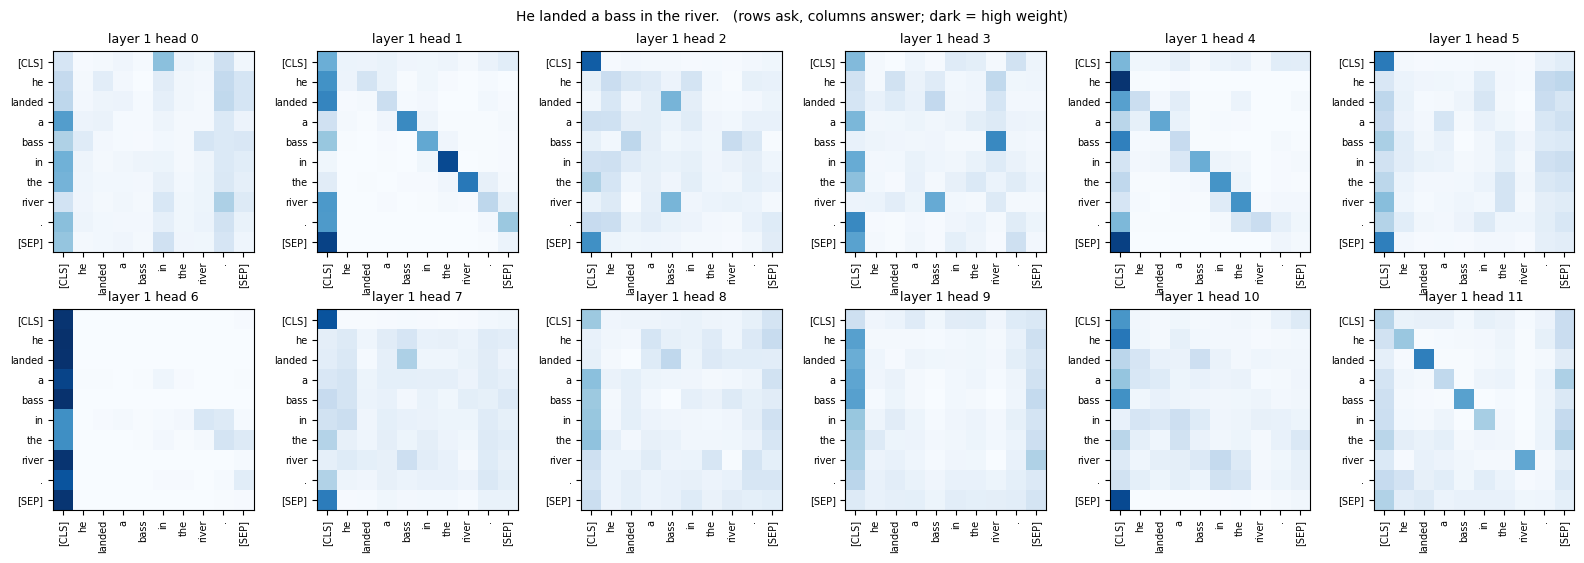

In [ ]:
def show_layer(name, L):
    assert isinstance(L, int) and 0 <= L < 12, "L must be a layer number from 0 to 11"
    toks = tokens[name]; n = len(toks)
    fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
    for h, ax in enumerate(axes.flat):
        ax.imshow(attn[name][L, h], cmap="Blues", vmin=0, vmax=1)
        ax.set_title(f"layer {L} head {h}", fontsize=9)
        ax.set_xticks(range(n)); ax.set_yticks(range(n))
        ax.set_xticklabels(toks, rotation=90, fontsize=7); ax.set_yticklabels(toks, fontsize=7)
    fig.suptitle(f'{sentences[name]}   (rows ask, columns answer; dark = high weight)', fontsize=10)
    plt.tight_layout(); plt.show()

show_layer("fish", 1)

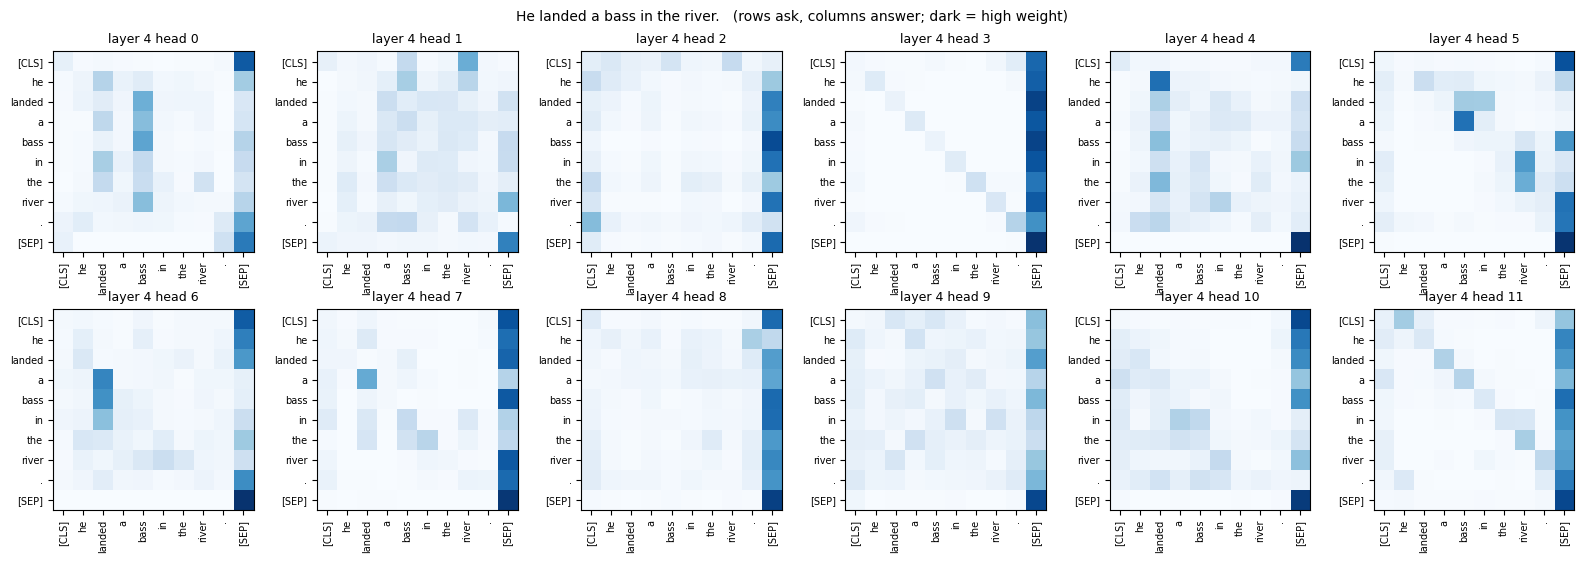

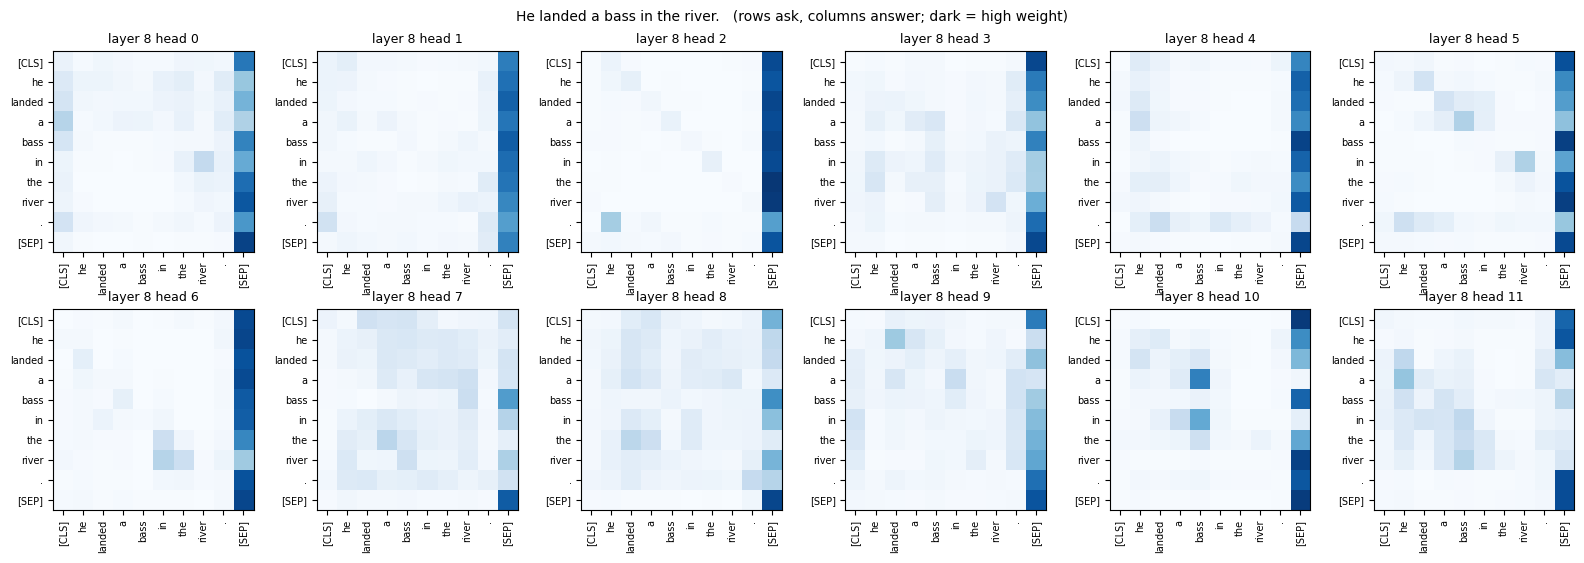

In [ ]:
# TODO: call show_layer for TWO more layers of your choice (one early, one from the middle or late).
show_layer("fish", 4)    # an early layer
show_layer("fish", 8)    # a middle layer


**Describe three heads by layer and head number: one whose pattern you can name (previous word? next word? the sentence boundary? a grammatical pair?), one that puts nearly all its weight on one column, and one you cannot read. Say what each row-to-column pattern is in words.**
> *Your answer:*
> - A pattern I can name (previous word): layer 4, head 3. The heat map is almost empty except for a thin dark diagonal running from the top left to the bottom right, plus a dark [SEP] column on the right edge. A diagonal means each asking word puts its weight on one specific neighbor instead of spreading it around. The line sits just under the main diagonal, so the neighbor is the word immediately before: landed looks at he, bass at a, and river at the. This head is doing “look one word back,” which is a position pattern, not a meaning pattern.
> - Nearly all weight on one column: layer 8, head 1. Every row is pale except the right-hand [SEP] column, which is dark from top to bottom. Whichever word is asking, this head sends almost everything to the same place, so it gives no information about how the words relate to each other. Several other layer 8 heads look the same, for example heads 0, 2 and 6.
> - One I cannot read: layer 4, head 8. The map is pale and spread out. I can see a faint [SEP] column and a few light blue patches near the bottom left, but no diagonal, no clear column and no isolated dark cell. I cannot describe a rule for what this head is doing.

**A bug, or a result? Several heads put almost everything on `[SEP]`, a token that carries no meaning. Is that a bug in the model, or a result? What might a head be doing when it attends to a token that says nothing?**
> *Your answer:*
> A result, not a bug, and my own heat maps show it. In layer 8 most heads are almost entirely a dark [SEP] column (heads 0 to 6 especially). Layer 4 is more mixed: heads 3 and 11 show diagonals and a few heads show isolated dark cells. The reason is that softmax makes each row sum to 1, so a head with nothing useful to do for a token still has to put its weight somewhere. [SEP] appears in every sentence, so it is a stable place to park. My best guess is that such a head is effectively switched off for that token: its output is mostly [SEP]’s value vector, which is roughly the same for every row and adds little token-specific information. Two cautions. Two side notes of the raw token, but by layer 8 its vector has been mixed with the whole sentence, so it might also be collecting sentence-level information. And a heat map shows where the weight goes, not what the head’s output does with it. I test this in my log.

### ✅ Verification checkpoint #2
Ask your AI assistant: *"Do BERT's attention heads correspond to linguistic functions — syntax, position,
coreference — or not?"* **Verify** against **your own heat maps** first — and, once you have done Part 5, **its counts** — then **Clark et
al. 2019, *What Does BERT Look At?*** (section 3 on the behaviour of heads, including attention to `[SEP]`)
and the **Attention lecture** (the "attention layers perform different tasks" slide). Report the mix you
actually found — the claim is open, and your own 144 heads are evidence. Record it in Part 6.

## Part 5 — Count, don't describe

Adjectives about heads are cheap. Clark et al. counted. Do the same in miniature: for every one of the
144 heads, three numbers —

- **sep_frac**: the share of the head's weight that lands on `[CLS]` or `[SEP]`, averaged over the asking tokens
- **prev_frac**: the share of asking tokens whose **heaviest** column is the token **before** them
- **next_frac**: the share whose heaviest column is the token **after** them

Then count heads: **boundary-parking** (sep_frac > 0.5), **previous-token** (prev_frac ≥ 0.6),
**next-token** (next_frac ≥ 0.6), and **other**. Report the counts per layer and in total.

In [ ]:
# TODO: write census(name) -> (sep_frac, prev_frac, next_frac, kind), all (12, 12) arrays:
#   A = attn[name]; toks = tokens[name]
#   special   = [j for j, tok in enumerate(toks) if tok in ("[CLS]", "[SEP]")]   positions of the two special tokens
#   sep_frac  = A[:, :, :, special].sum(-1).mean(-1)                share of weight on [CLS]/[SEP]
#   arg       = A.argmax(-1)                                        heaviest column for every asking token
#   prev_frac = share of asking tokens (from the 2nd on) whose heaviest column is their index - 1
#   next_frac = share of asking tokens (up to the 2nd-last) whose heaviest column is their index + 1
#   kind      = "boundary-parking" if sep_frac > 0.5, else "previous-token" if prev_frac >= 0.6,
#               else "next-token" if next_frac >= 0.6, else "other"
# Then, for each sentence, print a per-layer table of the four counts and the totals (they must sum to 144).


KINDS = ["boundary-parking", "previous-token", "next-token", "other"]

def census(name):
    A = attn[name]; toks = tokens[name]; n = len(toks)
    special = [j for j, t in enumerate(toks) if t in ("[CLS]", "[SEP]")]
    sep_frac = A[:, :, :, special].sum(-1).mean(-1)            # (12, 12): share of weight on [CLS]/[SEP]
    arg = A.argmax(-1)                                         # (12, 12, n): heaviest column per asking token
    idx = np.arange(n)
    prev_frac = (arg[:, :, 1:] == idx[1:] - 1).mean(-1)        # asking tokens 2nd..last
    next_frac = (arg[:, :, :-1] == idx[:-1] + 1).mean(-1)      # asking tokens 1st..2nd-last
    kind = np.full((12, 12), "other", dtype=object)            # assign in reverse priority so the
    kind[next_frac >= 0.6] = "next-token"                      # order of the rule in the brief wins:
    kind[prev_frac >= 0.6] = "previous-token"                  # boundary > previous > next > other
    kind[sep_frac > 0.5] = "boundary-parking"
    return sep_frac, prev_frac, next_frac, kind

for name in sentences:
    _, _, _, k = census(name)
    print(sentences[name])
    print(f"{'layer':>5}" + "".join(f"{x:>18}" for x in KINDS))
    for L in range(12):
        print(f"{L:>5}" + "".join(f"{int((k[L] == x).sum()):>18}" for x in KINDS))
    tot = [int((k == x).sum()) for x in KINDS]
    print(f"{'total':>5}" + "".join(f"{t:>18}" for t in tot), "  sum =", sum(tot), "\n")


He landed a bass in the river.
layer  boundary-parking    previous-token        next-token             other
    0                 2                 1                 1                 8
    1                 5                 0                 0                 7
    2                 6                 0                 2                 4
    3                 5                 1                 0                 6
    4                 8                 0                 0                 4
    5                11                 0                 1                 0
    6                 8                 0                 0                 4
    7                 8                 0                 0                 4
    8                 9                 0                 0                 3
    9                 9                 0                 0                 3
   10                 1                 0                 0                11
   11                 0          

In [ ]:
# Provided: does census() meet its contract?
_sf, _pf, _nf, _k = census("fish")
assert _sf.shape == _pf.shape == _nf.shape == _k.shape == (12, 12), "all four must be (12 layers, 12 heads)"
assert np.all((_sf >= 0) & (_sf <= 1 + 1e-6)) and np.all((_pf >= 0) & (_pf <= 1 + 1e-6)), "fractions must lie in [0, 1]"
_flat = list(_k.flat)
assert sum(_flat.count(x) for x in ("boundary-parking", "previous-token", "next-token", "other")) == 144, "the four kinds must account for all 144 heads"
print("census() OK —", _flat.count("boundary-parking"), "boundary-parking heads of 144 in the fish sentence")

census() OK — 72 boundary-parking heads of 144 in the fish sentence


**What fraction of heads could you name, and was your Q3 prediction right? Which layers hold the boundary-parking heads, and which hold none?**
> *Your answer:*

> In the fish sentence, 72 boundary-parking + 2 previous-token + 4 next-token = 78 of 144 heads (54%) had a pattern I could name. The other 66 were “other”. The music sentence was almost the same: 74 + 3 + 3 = 80 of 144 (56%), with 64 “other”. My Q3 guess of 70% was too high by about 15 points. I had pictured the nameable heads as grammatical, but most of them (72 of 78 in the fish sentence) are heads parked on [CLS]/[SEP]. Only 6 heads (4%) were previous-token or next-token heads, so that is the only kind of position pattern I found.

> The boundary-parking heads sit mostly in the middle of the model. In the fish sentence they appear in layers 0 to 10 but cluster in layers 4 to 9, which hold 53 of the 72. Layer 5 is the extreme, with 11 of its 12 heads parked. Layer 11 holds none, and layers 0 and 10 hold only 2 and 1. The music sentence shows the same shape: layers 4 to 9 hold 59 of its 74 boundary heads, and layers 10 and 11 hold none. The few previous-token and next-token heads are almost all in layers 0 to 3 (the one exception is a single next-token head in layer 5 of the fish sentence). Layers 10 and 11 have no named heads at all (12 “other” each, except one parked head in fish layer 10). I can’t say what the last layers are doing, only that they don’t follow any of the three patterns I counted.

**Two sentences is a tiny sample. Name one thing about these counts you would expect to change on a 30-word sentence, and one you would expect to hold.**
> *Your answer:*

> One thing I expect to change is the heads near the 0.5 cut-off for boundary-parking. Here [CLS] and [SEP] are 2 of 10 columns, but in a 30-word sentence they would be 2 of about 32. A head that spreads its weight thinly would see its share on the special tokens fall (an even spread gives 0.2 here and about 0.06 there), so borderline heads, such as the ones in layers 1 to 3 and layer 0, could flip to “other”. A head that puts well over half its weight on [SEP] would stay a boundary-parking head.

> One thing I expect to hold is the overall shape. The two sentences gave nearly the same totals (72 and 74 boundary-parking, with previous-token and next-token counts of only 2 to 4 each) and the same layer pattern (parked heads in the middle layers, none in layer 11). Two different sentences agreeing so closely suggests the pattern doesn’t depend on the particular words. These are expectations, not results, since I haven’t run a 30-word sentence.

## Part 6 — AI Verification Log

One block per checkpoint: the **question you asked**, the **claim** that came back, the **source** you
checked it against, your **verdict**, and **what you found when you checked** — what the source actually
said, or what your own output actually showed. Then add at least one claim you chose yourself.

**How the log is graded** — the same four rows as the assignment page:
- **The question.** A real question, and a follow-up where the first answer was thin. *"Isn't attention
  just a weighted average?"* is fishing for agreement; *"What does the softmax over Q·Kᵀ compute?"* is a question.
- **Source quality.** The right kind for the kind of claim: the textbook, the lecture or the paper for a
  definition or a research finding, the Hugging Face docs for how a function behaves, **your own output**
  for a claim about what this model does on these sentences.
- **Thoroughness.** Every checkpoint, plus a claim you chose yourself.
- **What you found.** The finding says what the source *said* or what your output *showed*. Naming a
  caveat, a boundary condition, or a case where the claim breaks is what makes a block excellent
  rather than satisfactory. The AI does not have to be wrong.

*(Double-click this cell to edit. Type after each bold label, then Shift+Enter to render it.)*

**A worked example, filled in so you can see the bar.** This one is not yours to answer:

- **What you asked:** "When I pass `output_attentions=True`, are the returned matrices the softmax weights, or the raw Q·Kᵀ scores?"
- **What it told you:** They are the attention weights after the softmax, one matrix per head.
- **Source checked:** Hugging Face `BertModel` docs (the `attentions` output), plus my own Part 4 output
- **Verdict:** ✅ correct, with a caveat
- **What you found when you checked:** The docs say `attentions` are "the attention weights after the attention softmax", one per layer, shaped (batch, heads, tokens, tokens). My Part 4 rows summed to 1.0, which raw scores would not. The caveat the AI did not mention: the weights are only guaranteed with `attn_implementation="eager"` — the fast attention kernels never materialise the weight matrix, so the library either falls back to the slow path with a warning or returns nothing.

**The same block, written the way that does not count.** Same question, same source:

- **What you found when you checked:** The docs confirm they are the attention weights. ✅

That repeats the claim. It does not say what the docs said, and it did not look at the output. A
finding that could have been written without opening the source is not a check.

---

### Claim 1 — checkpoint #1
- **What you asked:** "Why does scaled dot-product attention divide the scores by √d? What would happen
without it?"
- **What it told you:** Dot products of d-dimensional vectors with independent, zero-mean, unit-variance entries have variance d, so the scores grow like √d. Big scores push the softmax into a near-one-hot state where its gradients vanish; dividing by √d puts the variance back at 1. Follow-up answer: "d is the vector dimension — 768 for BERT-base — so BERT divides by √768 ≈ 27.7."
- **Source checked:** My Part 2 output (the toy and the d = 2 … 512 table); the Attention lecture (the Scaled Dot-Product Attention slides); SLP3, the Transformers chapter, self-attention section
- **Verdict:** ⚠️ right mechanism, wrong number for BERT
- **What you found when you checked:** *My output (supports the direction, with a limit).* Unscaled, the largest weight was 0.115, 0.280, 0.998, 0.889 for d = 2, 16, 64, 512; scaled it stayed between 0.110 and 0.319, and the spread of the raw scores grew from 0.11 to 20.6. The limit the AI did not mention: each row is one random draw of 10 keys, so d = 512 (0.889) sits *below* d = 64 (0.998). The claim is about the typical spread, not every draw, and at d = 2 the scale changed almost nothing (0.115 vs 0.110). My own code also drew N(0, 1) entries, which is exactly the assumption the variance argument needs. Trained vectors are not guaranteed to satisfy it, so the scale is a sensible default rather than a proof. My output shows saturation; it cannot show "training stalls".
  - *Lecture* The SDPA slides show the Scale step and describe attention as finding query–key similarity, but nowhere say why the scores are scaled. The lecture confirms only that the step exists, so it could not settle the AI's explanation.
  - *Book (caveat found).* SLP3 gives the same reason in terms of numerical trouble and lost gradients when large scores are exponentiated, but it writes the divisor as √d_k — the dimensionality of the query and key vectors *of a head*. In multi-head attention that is d_model / h, not the model's embedding size.

### Claim 2 — checkpoint #2
- **What you asked:** "Do BERT's attention heads correspond to linguistic functions — syntax, position,
coreference — or not?"
- **What it told you:** Largely yes. Individual heads specialise: some attend to the previous or next token (position), some track syntactic relations such as verb → object and noun → determiner, and some link pronouns to their antecedents (coreference). Early layers lean positional, middle layers syntactic, upper layers semantic.
- **Source checked:** My Part 4 heat maps and Part 5 counts; Clark *What Does BERT Look At?*, section 3; the Attention lecture, the "Positional Heads / Syntactic Heads" slide and the "Attention Layers Perform Different Tasks" slide.
- **Verdict:** ⚠️ partly right / needs caveat
- **What you found when you checked:**
- *My output (position yes but rare, syntax and coreference untested).* In the fish sentence 2 heads were previous-token and 4 were next-token, so position patterns exist, but they make up only 6 of 144 heads (4%). Nearly all of them are in layers 0 to 3, which matches the AI's claim that early layers lean positional. But 72 heads were boundary-parking and 66 were "other", and nothing in my counts shows syntax or coreference. A single 10-token sentence and my three simple rules could not detect either.
- *Paper (caveat found).* Clark et al. do find individual heads that line up with particular relations (verbs and their objects, determiners) and a coreference-like head, but they got these by searching across all heads, and they stress that no single head does syntax overall. They also report that a large share of the attention in the middle layers lands on `[SEP]`, which they read as a "do nothing" target rather than a linguistic function. The AI presented specialisation as the typical case and never mentioned `[SEP]`. My own census agrees with the paper: half the heads (72 of 144) are parked on `[CLS]`/`[SEP]`, and 53 of those are in layers 4 to 9.

### Claim 3 — one you chose yourself
*A claim about what this model does is checked against your own output — a head from Part 4, or the
counts from Part 5, belong here.*
- **What you asked:** I pasted my `bass_looks_at` output for both sentences and asked: "Does this show BERT's heads disambiguating *bass*?" The answer quoted weights without saying how large they were relative to the row, so I followed up: "How big are those weights compared with the whole row?"
- **What it told you:** Yes — in some layers bass's strongest content-word attention goes to *river* in the fish sentence and to a music word in the other, so heads are picking up the context words that separate the senses. It added its own caution: attention weights are not the same as explanations, so this is suggestive rather than proof. Follow-up answer: the weights are probabilities that sum to 1 across the row, so 0.3 means 30% of that head's attention.
- **Source checked:** My own Part 4 output (both sentences, `bass_looks_at` and the heat maps); the Hugging Face `BertModel` docs (the `attentions` output) and the tokenizer docs (special tokens are added by default); my own `bass_looks_at` code.
- **Verdict:** ⚠️ partly right / needs caveat
- **What you found when you checked:**
  - *My output (the AI's caution holds, and it is selective).* The two sentences contain different words, so the winning word will often differ between them for that reason alone. A different winner is not evidence of disambiguation. What counts is whether *river* wins in the fish sentence and a music word (*plucked* or *song*) wins in the music sentence. In my table that happens in only some of the 12 layers; in the others the winner is a word like *he* or *landed* that has nothing to do with the sense. So the evidence is partial, which is what the AI's "suggestive" hinted at.
  - *API (caveat the AI missed: the missing mass).* The docs say `attentions` are the post-softmax weights, so each row sums to 1 across all ten columns, including `[CLS]` and `[SEP]`, which the tokenizer inserts by default. My `bass_looks_at` throws those columns (and the function words *the*, *a*, *in*) away before taking the maximum, so the weight it reports is a share of the *whole* row, not of the content words alone. The best content-word weight in each layer is well below 1, so most of bass's attention in that head went to the columns I skipped. The AI's follow-up ("0.3 means 30% of the attention") was true but never said where the other 70% went.
  - *Code (caveat the AI missed: selection effect).* For each layer I take the maximum over 12 heads × only three content columns (*he*, *landed*, *river*) — 36 cells — so *some* word always wins (*river* only has to beat two rivals), and picking the best-fitting head per layer finds a head that matches the story by construction. To claim disambiguation I would need the same head to behave this way across many sentences; two sentences cannot show it.

**Verdict key:** ✅ correct · ⚠️ partly right / needs caveat · ❌ wrong.

## Part 7 — Save your artifact (shared format → final project)

In [ ]:
# TODO: Build a dict `artifact` in the shared envelope
#   {"week": 8, "task": "attention", "source": "...", "outputs": {...}}
# `outputs` is a DICT with named keys. Fill it from the variables and calls in this notebook, not by
# typing values in: the toy's scaled weights, unscaled weights and output (Part 1-2); bass_looks_at(...)
# for both sentences (Part 4); the head census counts for the fish sentence (Part 5); and ONE full
# attention matrix -- the layer-1 head-3 table for the fish sentence, as a dict with the keys "tokens"
# (the token list) and "matrix" (the 10x10 table as a list of lists; the check cell looks for "matrix"). Convert numpy
# values with float(...) / .tolist() or json.dump will refuse them. Save it with json.dump as
# talktorial5_artifact.json, then print it (you may leave the big matrix out of the print).
sf, pf, nf, kind = census("fish")
artifact = {
    "week": 8,
    "task": "attention",
    "source": "Talktorial 5: hand-built scaled dot-product attention (numpy) + bert-base-uncased attentions (Hugging Face)",
    "outputs": {
        "toy_scaled_weights":   attention(q, K, V, scale=True)[1].tolist(),
        "toy_unscaled_weights": attention(q, K, V, scale=False)[1].tolist(),
        "toy_output":           attention(q, K, V, scale=True)[2].tolist(),
        "bass_looks_at_fish":   [list(r) for r in bass_looks_at("fish")],
        "bass_looks_at_music":  [list(r) for r in bass_looks_at("music")],
        "census_fish":          {x: int((kind == x).sum()) for x in KINDS},
        "layer1_head3_fish":    {"tokens": tokens["fish"], "matrix": attn["fish"][1, 3].tolist()},
    },
}
with open("talktorial5_artifact.json", "w") as f:
    json.dump(artifact, f)
printable = {k: v for k, v in artifact["outputs"].items() if k != "layer1_head3_fish"}
print(json.dumps({**artifact, "outputs": printable}, indent=1)[:1800])


{
 "week": 8,
 "task": "attention",
 "source": "Talktorial 5: hand-built scaled dot-product attention (numpy) + bert-base-uncased attentions (Hugging Face)",
 "outputs": {
  "toy_scaled_weights": [
   0.04538836291379466,
   0.18669370094750284,
   0.7679179361387025
  ],
  "toy_unscaled_weights": [
   0.015876239976466765,
   0.11731042782619838,
   0.8668133321973349
  ],
  "toy_output": [
   0.13873521338754607,
   0.861264786612454
  ],
  "bass_looks_at_fish": [
   [
    0,
    8,
    "river",
    0.37785011529922485
   ],
   [
    1,
    3,
    "river",
    0.6563751101493835
   ],
   [
    2,
    10,
    "river",
    0.29851409792900085
   ],
   [
    3,
    8,
    "landed",
    0.5343107581138611
   ],
   [
    4,
    6,
    "landed",
    0.6252938508987427
   ],
   [
    5,
    10,
    "landed",
    0.050144024193286896
   ],
   [
    6,
    9,
    "landed",
    0.4560926854610443
   ],
   [
    7,
    0,
    "he",
    0.21134284138679504
   ],
   [
    8,
    7,
    "river",
 

In [ ]:
# Provided: checks the artifact is in the shared shape. If it fails, fix the cell above.
import json, os
assert os.path.exists("talktorial5_artifact.json"), "talktorial5_artifact.json was not written"
_a = json.load(open("talktorial5_artifact.json"))
_missing = {"week", "task", "source", "outputs"} - set(_a)
assert not _missing, f"envelope is missing {_missing}"
assert isinstance(_a["outputs"], dict) and _a["outputs"], "outputs must be a non-empty dict with named keys"
assert any(isinstance(v, dict) and "matrix" in v for v in _a["outputs"].values()), "include one full attention matrix"
print("artifact OK — outputs keys:", sorted(_a["outputs"]))

artifact OK — outputs keys: ['bass_looks_at_fish', 'bass_looks_at_music', 'census_fish', 'layer1_head3_fish', 'toy_output', 'toy_scaled_weights', 'toy_unscaled_weights']


## Before you submit — a few questions, honestly answered

These are not graded for being impressive. They are graded for being real, and they are
how I find out what is not landing while there is still time to do something about it.
*(Double-click this cell to type your answers, then Shift+Enter.)*

**1. What surprised you?**
*(Scroll back to your predictions at the top — where was your intuition wrong, and why?)*

> *Your answer:* My Q3 guess. I predicted about 70% of the 144 heads would show a pattern I could name, because the lecture slides show positional and syntactic heads as if that is what heads are. My census says only 54% (78 of 144) in the fish sentence and 56% in the music sentence, so I was about 15 points too high. The bigger surprise was what the nameable ones are: 72 of those 78 are heads parked on [CLS]/[SEP], and only 6 are previous-token or next-token heads. Nothing I counted was grammar. My intuition was wrong because the lecture slides show a few hand-picked heads from a translation model, so I treated the best examples as typical.


**2. What got you stuck this week, and what did you do about it?**
*("I am still stuck on X" is a complete and fully-credited answer.)*

> *Your answer:* Row-wise softmax in Part 3: my first version used `.sum()` instead of `.sum(axis=1, keepdims=True)`, so the whole table summed to 1 instead of each row, and the "rows must sum to 1" check caught it. In `bass_looks_at` I also printed the column index from the filtered list instead of the real token until I mapped it back with `keep[c]`.

**3. What is one question you still have?**

> *Your answer:* If so many heads park on `[SEP]` and act as a no-op, could they be removed without hurting BERT — and does a large attention weight really mean that token *influenced* the output?

---

### Working with AI

*There is no right answer here — "it frustrated me" and "I am not sure it helped" are as useful to me as anything positive. Answer honestly rather than helpfully.*

**a. Which AI did you use this week?** Name the assistant, and the model if you know it — e.g. "ChatGPT", "Claude", "Gemini", "Copilot", a local model, or "none this week", which is a perfectly good answer.

> *Your answer:* Copilot

**b. After completing this week’s AI-supported task and checking the AI’s response, what did you think and feel about your experience with AI?**

*You might reflect on things such as what surprised you, what confused or frustrated you, what helped you learn, what made you feel more or less confident, or whether checking the AI’s response changed your thinking or feelings.*

> *Your answer:* The answers were fluent and mostly right, which made me trust them more than I should have. Every time I checked, something was missing like BERT's d is 64 per head, not 768, etc. Checking made me less sure of the AI's tone but surer of my own understanding, and it changed what I did next when I would verify findings.



## Wrap-up

You pushed numbers through **softmax(q·Kᵀ/√d)·V** by hand and watched bass's vector move toward *river*;
you saw why the **√d** is there — without it the softmax saturates as the dimension grows and nothing can
learn; you built **self-attention** from Q, K and V and saw that it is **not symmetric**, and **masked** it
the way a decoder must. Then you opened a real **BERT**: some early heads really do send *bass* to *river*
in one sentence and *song* in the other, some heads track the neighbouring word, and about half of all 144
heads — nearly all of them in the middle layers — park on `[SEP]` — a mix you **counted** rather than asserted, and carried into
your log as an open claim.

In the Transformer Models lecture the heads become a **Transformer**: the encoder stack (BERT) and the
decoder stack (GPT). The next talktorial brings the payoff planted in the Embeddings week — what BERT's
**contextual vector** for *bass* does across these same two sentences, measured layer by layer.

**Optional extensions:** run a 30-word sentence through `census` and see which counts move; find the head
with the highest weight on a *pronoun → antecedent* pair in a sentence of your own; swap in
`distilbert-base-uncased` (6 layers) and compare the census.

**Submit:** Run all cells, then **File → Download .ipynb** → upload to Canvas with the Verification
Log completed.

---

## Stuck for more than thirty minutes? Hints

Try without these first — working it out is where the points are. Using a hint costs nothing.

**Part 1, `softmax`.** `e = np.exp(x - np.max(x))`, then `e / e.sum()`. Subtracting the max changes nothing
about the result and stops `exp` from overflowing.

**Part 1, `attention`.** `K @ q` gives one score per key. Divide by `math.sqrt(K.shape[1])`. The output is
`weights @ V`.

**Part 3, row-wise softmax.** `np.exp(S - S.max(axis=1, keepdims=True))`, then divide by the row sums with
`axis=1, keepdims=True`. For the mask, `np.where(mask, -np.inf, S)` before the exponential; `exp(-inf)` is 0.

**Part 4, bass's row.** `attn[name][L, :, b, :]` is a (12 heads × tokens) slice. Keep only the content-word
columns, then `np.unravel_index(sub.argmax(), sub.shape)` gives (head, column).

**Part 5, `argmax`.** `A.argmax(-1)` has shape (12, 12, tokens): for every asking token, the index of the
column it weights most. Compare it with `np.arange(n) - 1` (previous) and `+ 1` (next), dropping the first or
last position.